# Dream in Orbit: data exploration
## 1. Load the power data
power.csv has 1,830,121 rows (a measurement about every 32 s) and 33 circuits (NPWD...) to predict.

In [2]:
import pandas as pd

power = pd.read_csv("annee1/power.csv")
print(power.shape)
power.head()

(1830121, 34)


,ut_ms,NPWD2372,NPWD2401,NPWD2402,NPWD2451,NPWD2471,NPWD2472,NPWD2481,NPWD2482,NPWD2491,...,NPWD2792,NPWD2801,NPWD2802,NPWD2821,NPWD2851,NPWD2852,NPWD2871,NPWD2872,NPWD2881,NPWD2882
0,1219363209542,0.001821,0.001474,0.172173,0.005015,0.000714,0.000626,0.000665,0.001827,0.002016,...,0.000553,0.001474,0.156296,0.005547,0.004982,0.000501,0.000399,0.000714,0.006457,0.003227
1,1219363241537,0.002185,0.001769,0.177440,0.006019,0.000714,0.000751,0.000554,0.001827,0.430256,...,0.000553,0.001474,0.156296,0.005547,0.004982,0.000501,0.000499,0.000857,0.007748,0.003227
2,1219363273542,0.002185,0.001474,0.172173,0.005015,0.000571,0.000626,0.000554,0.001827,0.430256,...,0.000664,0.001474,0.161594,0.005547,0.004982,0.000501,0.000499,0.000571,0.006457,0.003227
3,1219363305537,0.001821,0.001474,0.172173,0.005015,0.000714,0.000751,0.000554,0.001827,0.424989,...,0.000664,0.001474,0.156296,0.006657,0.004982,0.000501,0.000598,0.000571,0.006457,0.003227
4,1219363337542,0.001821,0.001769,0.177440,0.005015,0.000714,0.000751,0.000554,0.001827,0.430256,...,0.000553,0.001474,0.161594,0.005547,0.004982,0.000501,0.000499,0.000714,0.006457,0.002582


## 2. Convert to hourly data
Average the measurements into one row per hour: 16,488 hours, 2008-08-22 to 2010-07-09.

In [4]:
power["time"] = pd.to_datetime(power["ut_ms"], unit="ms")
print(power["time"].min(), "->", power["time"].max())

hourly = power.set_index("time").drop(columns="ut_ms").resample("1h").mean()
print(hourly.shape)
print("missing values:", hourly.isna().sum().sum())
hourly.head()

2008-08-22 00:00:09.542000 -> 2010-07-09 23:59:36.556000
(16488, 33)
missing values: 1056


,NPWD2372,NPWD2401,NPWD2402,NPWD2451,NPWD2471,NPWD2472,NPWD2481,NPWD2482,NPWD2491,NPWD2501,...,NPWD2792,NPWD2801,NPWD2802,NPWD2821,NPWD2851,NPWD2852,NPWD2871,NPWD2872,NPWD2881,NPWD2882
time,,,,,,,,,,,,,,,,,,,,,
2008-08-22 00:00:00,0.133582,0.001552,0.175436,0.657240,0.000747,0.000661,0.000585,0.001927,0.244648,0.005277,...,0.000573,0.001526,0.159719,0.005753,0.005273,0.000529,0.000525,0.000762,0.006765,0.003382
2008-08-22 01:00:00,0.217001,0.001498,0.175888,0.854918,0.000717,0.000628,0.000551,0.001834,0.230870,0.005010,...,0.000560,0.001484,0.046897,0.005607,0.005035,0.000510,0.000503,0.000728,0.006595,0.003268
2008-08-22 02:00:00,0.155922,0.001503,0.175389,1.079016,0.000719,0.000636,0.000568,0.001856,0.202746,0.005135,...,0.000573,0.001508,0.281516,0.005685,0.005097,0.000514,0.000513,0.000731,0.006571,0.003296
2008-08-22 03:00:00,0.081440,0.001532,0.175324,0.720677,0.000742,0.000647,0.000570,0.001892,0.212218,0.005162,...,0.000578,0.001521,0.142337,0.005745,0.005249,0.000527,0.000517,0.000747,0.006734,0.003423
2008-08-22 04:00:00,0.103773,0.001505,0.174224,0.828578,0.000738,0.000642,0.000560,0.001879,0.228923,0.005170,...,0.000566,0.001521,0.057978,0.005753,0.005176,0.000525,0.000525,0.000740,0.006685,0.003370


## 3. Gaps and first look
32 hours with no data at all (2009-03-15 and 2009-07-31). Most variable circuits: NPWD2551, NPWD2451, NPWD2532, NPWD2531. NPWD2451 has a long low-consumption period in the middle, which looks like a change of operating mode.

Number of fully empty hours: 32
DatetimeIndex(['2009-03-15 08:00:00', '2009-03-15 09:00:00',
               '2009-03-15 14:00:00', '2009-03-15 15:00:00',
               '2009-03-15 16:00:00', '2009-03-15 21:00:00',
               '2009-03-15 22:00:00', '2009-03-15 23:00:00',
               '2009-07-31 00:00:00', '2009-07-31 01:00:00'],
              dtype='datetime64[ns]', name='time', freq=None)
NPWD2551    0.398334
NPWD2451    0.305266
NPWD2532    0.261925
NPWD2531    0.243684
NPWD2881    0.170522
NPWD2851    0.156923
NPWD2561    0.151029
NPWD2721    0.082764
NPWD2802    0.078640
NPWD2791    0.076572
dtype: float64


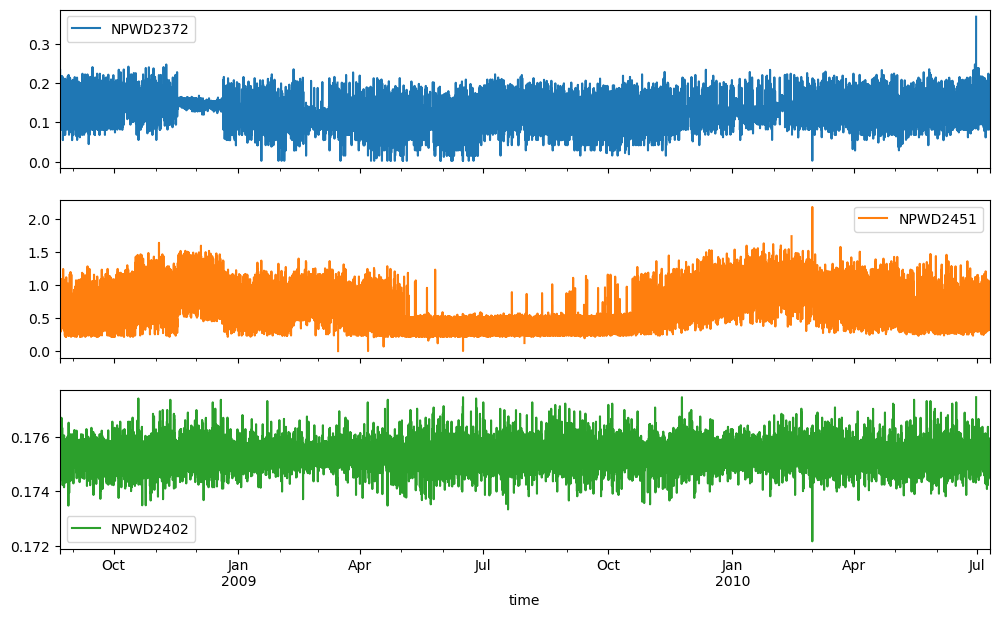

In [5]:
import matplotlib.pyplot as plt

# 1. Which hours are missing?
missing_hours = hourly[hourly.isna().all(axis=1)].index
print("Number of fully empty hours:", len(missing_hours))
print(missing_hours[:10])

# 2. Which circuits vary the most? (higher std = more to predict)
print(hourly.std().sort_values(ascending=False).head(10))

# 3. Plot 3 circuits over the whole period
hourly[["NPWD2372", "NPWD2451", "NPWD2402"]].plot(subplots=True, figsize=(12, 7))
plt.show()

## 4. Fill gaps and create the validation set
Fill the 32 empty hours by interpolation. make_validation.py hides annee2 and keeps only its first 7 days: 16,319 hours to predict, 2010-07-17 to 2012-05-26.

In [6]:
# Fill the 32 empty hours by interpolating between neighboring hours
hourly = hourly.interpolate(method="time").bfill().ffill()
print("missing values left:", hourly.isna().sum().sum())

# Save so we never have to recompute it
hourly.to_csv("hourly_annee1.csv")

missing values left: 0


In [7]:
!python make_validation.py --annee annee2 --out validation

16319 heures à prédire, de 2010-07-17 01:00:00 à 2012-05-26 23:00:00


In [8]:
import os
for root, dirs, files in os.walk("validation"):
    print(root, files)

heures = pd.read_csv("validation/test/heures_a_predire.csv")
verite = pd.read_csv("validation/verite_horaire.csv")
print(heures.shape, verite.shape)
print(heures.head(3))
print(verite.head(3))
print(verite.columns.tolist()[:5])

validation ['verite_horaire.csv']
validation\test ['dmop.csv', 'evtf.csv', 'ftl.csv', 'heures_a_predire.csv', 'ltdata.csv', 'power_init.csv', 'saaf.csv']
(16319, 1) (16073, 34)
           ut_ms
0  1279328400000
1  1279332000000
2  1279335600000
           ut_ms  NPWD2372  NPWD2401  NPWD2402  NPWD2451  NPWD2471  NPWD2472  \
0  1279328400000  0.120512  0.001474  0.176217  0.373741  0.000714  0.000626   
1  1279332000000  0.113494  0.001487  0.175296  0.544487  0.000721  0.000631   
2  1279335600000  0.114070  0.001484  0.174901  0.325562  0.000719  0.000631   

   NPWD2481  NPWD2482  NPWD2491  ...  NPWD2792  NPWD2801  NPWD2802  NPWD2821  \
0  0.000554  0.001827  0.208489  ...  0.000553  0.001474  0.116944  0.005547   
1  0.000557  0.001846  0.206672  ...  0.000558  0.001482  0.048212  0.005577   
2  0.000560  0.001850  0.185558  ...  0.000558  0.001490  0.133245  0.005607   

   NPWD2851  NPWD2852  NPWD2871  NPWD2872  NPWD2881  NPWD2882  
0  0.291681  0.000501  0.000499  0.000714  0.7202

## 5. Baseline: constant prediction
Predict the annee1 mean of each circuit for every hour. RMSE = 0.105753. Any model must beat this.

In [9]:
# Average of each circuit over annee1 (this is the "constant" prediction)
mean_per_circuit = hourly.mean()

# Use the exact hours and column order of the answer file
heures = pd.read_csv("validation/test/heures_a_predire.csv")
verite = pd.read_csv("validation/verite_horaire.csv")
circuits = verite.columns[1:]          # the 33 circuit names

pred = pd.DataFrame({"ut_ms": heures["ut_ms"]})
for c in circuits:
    pred[c] = mean_per_circuit[c]

pred.to_csv("pred_constant.csv", index=False)
print(pred.shape)

(16319, 34)


In [10]:
!python evaluate.py --pred pred_constant.csv --verite validation/verite_horaire.csv --heures validation/test/heures_a_predire.csv

RMSE = 0.105753  (530409 valeurs notées sur 16073 heures)


In [11]:
for name in ["dmop", "ftl", "saaf", "evtf", "ltdata"]:
    df = pd.read_csv(f"annee1/{name}.csv")
    print("=====", name, df.shape)
    print(df.columns.tolist())
    print(df.head(3))
    print()

===== dmop (187126, 2)
['ut_ms', 'subsystem']
           ut_ms  subsystem
0  1219363211000   AXXX301A
1  1219364909000  AAAAF20C1
2  1219364914000  AAAAF57A1

===== ftl (19571, 4)
['utb_ms', 'ute_ms', 'type', 'flagcomms']
          utb_ms         ute_ms   type  flagcomms
0  1219363213000  1219365494000  EARTH      False
1  1219365494000  1219369555000  EARTH       True
2  1219369555000  1219369619000  EARTH      False

===== saaf (1261290, 5)
['ut_ms', 'sa', 'sx', 'sy', 'sz']
           ut_ms    sa     sx     sy      sz
0  1219363213000  0.32  14.55  90.32  104.55
1  1219363235000  0.34  14.56  90.34  104.55
2  1219363295000  0.34  14.56  90.34  104.55

===== evtf (76776, 2)
['ut_ms', 'description']
           ut_ms              description
0  1219364253000  MLG_LOS_05_/_RTLT_02373
1  1219364356000  NNO_AOS_00_/_RTLT_02373
2  1219365058000  MLG_LOS_02_/_RTLT_02373

===== ltdata (687, 7)
['ut_ms', 'sunmars_km', 'earthmars_km', 'sunmarsearthangle_deg', 'solarconstantmars', 'eclipsedurati

## 6. Context files
ftl = pointing modes and communications, saaf = Sun angles, evtf = events (passages, ground-station contacts), dmop = commands (9,280 distinct, grouped by first 4 letters), ltdata = daily trends.

In [12]:
ftl = pd.read_csv("annee1/ftl.csv")
print(ftl["type"].value_counts())
print(ftl["flagcomms"].value_counts())

evtf = pd.read_csv("annee1/evtf.csv")
evtf["kind"] = evtf["description"].str.split(r"[_ ]").str[:2].str.join("_")
print(evtf["kind"].value_counts().head(25))

dmop = pd.read_csv("annee1/dmop.csv")
print("distinct dmop commands:", dmop["subsystem"].nunique())
print(dmop["subsystem"].str[:4].value_counts().head(15))

type
SLEW             7268
EARTH            6700
INERTIAL         1811
NADIR             929
WARMUP            722
MAINTENANCE       641
RADIO_SCIENCE     548
ACROSS_TRACK      367
D4PNPO            327
D1PVMC            217
SPECULAR           32
D5PPHB              4
D3POCM              3
D2PLND              2
Name: count, dtype: int64
flagcomms
False    16505
True      3066
Name: count, dtype: int64
kind
OCC_MARS              5730
4000_KM               4778
2000_KM               4778
1200_KM               4778
800_KM                4778
MRB_/                 4372
MRB_LOS               2954
MRB_AOS               2954
PERICENTRE_PASSAGE    2389
APOCENTRE_PASSAGE     2388
NNO_LOS               2064
CAN_LOS               2064
MAD_AOS               2064
CEB_AOS               2064
MLG_AOS               2064
MAD_LOS               2064
GDS_LOS               2064
GDS_AOS               2064
CEB_LOS               2064
NNO_AOS               2064
MLG_LOS               2063
BLK_LOS               2

In [13]:
import numpy as np

H = 3_600_000                                   # one hour in ms
t0 = int(hourly.index[0].value // 10**6)        # first hour, in ms
n = len(hourly)

def overlap_fraction(starts, ends):
    """Fraction of each hour covered by the periods [start, end]."""
    out = np.zeros(n)
    for s, e in zip(starts, ends):
        s, e = s - t0, e - t0
        s, e = max(s, 0), min(e, n * H)
        h = s // H
        while h * H < e:
            out[h] += (min(e, (h + 1) * H) - max(s, h * H)) / H
            h += 1
    return np.clip(out, 0, 1)

features = pd.DataFrame(index=hourly.index)

# 1) Pointing modes and communication (share of the hour)
ftl = pd.read_csv("annee1/ftl.csv")
for t in ["SLEW", "EARTH", "INERTIAL", "NADIR", "WARMUP", "MAINTENANCE", "RADIO_SCIENCE", "ACROSS_TRACK"]:
    sub = ftl[ftl["type"] == t]
    features["ftl_" + t] = overlap_fraction(sub["utb_ms"], sub["ute_ms"])
comms = ftl[ftl["flagcomms"].astype(str) == "True"]
features["ftl_comms"] = overlap_fraction(comms["utb_ms"], comms["ute_ms"])

# 2) Sun angles (hourly mean)
saaf = pd.read_csv("annee1/saaf.csv")
saaf["time"] = pd.to_datetime(saaf["ut_ms"], unit="ms")
saaf_h = saaf.set_index("time")[["sa", "sx", "sy", "sz"]].resample("1h").mean()
features[["sa", "sx", "sy", "sz"]] = saaf_h.reindex(hourly.index).interpolate().bfill().ffill()

# 3) Daily trends, interpolated to hourly
lt = pd.read_csv("annee1/ltdata.csv")
lt["time"] = pd.to_datetime(lt["ut_ms"], unit="ms")
lt = lt.set_index("time").drop(columns="ut_ms")
lt_h = lt.reindex(lt.index.union(hourly.index)).interpolate(method="time").reindex(hourly.index).bfill().ffill()
features = features.join(lt_h)

# 4) Event counts per hour (15 most common kinds)
evtf = pd.read_csv("annee1/evtf.csv")
evtf["kind"] = evtf["description"].str.split(r"[_ ]").str[:2].str.join("_")
evtf["hour"] = (evtf["ut_ms"] - t0) // H
ev = evtf[(evtf["hour"] >= 0) & (evtf["hour"] < n)]
ev_counts = ev.groupby(["hour", "kind"]).size().unstack(fill_value=0)
top_kinds = evtf["kind"].value_counts().head(15).index
ev_counts = ev_counts.reindex(index=range(n), columns=top_kinds, fill_value=0)
ev_counts.index = hourly.index
features = features.join(ev_counts.add_prefix("evt_"))

# 5) Command counts per hour (12 most common families)
dmop = pd.read_csv("annee1/dmop.csv")
dmop["fam"] = dmop["subsystem"].str[:4]
dmop["hour"] = (dmop["ut_ms"] - t0) // H
dm = dmop[(dmop["hour"] >= 0) & (dmop["hour"] < n)]
dm_counts = dm.groupby(["hour", "fam"]).size().unstack(fill_value=0)
top_fams = dmop["fam"].value_counts().head(12).index
dm_counts = dm_counts.reindex(index=range(n), columns=top_fams, fill_value=0)
dm_counts.index = hourly.index
features = features.join(dm_counts.add_prefix("cmd_"))

print(features.shape)
print("missing:", features.isna().sum().sum())

# Which features move together with the most variable circuits?
for c in ["NPWD2551", "NPWD2451", "NPWD2532"]:
    print("\n", c)
    print(features.corrwith(hourly[c]).abs().sort_values(ascending=False).head(8))

# Look for eclipse-like events in evtf
print(evtf[evtf["description"].str.contains("UMBRA|PENUMBRA|ECLIPSE", case=False)]["kind"].value_counts().head())

(16488, 46)
missing: 0

 NPWD2551
eclipseduration_min        0.588440
earthmars_km               0.503675
ftl_EARTH                  0.432674
occultationduration_min    0.369649
evt_OCC_MARS               0.349547
ftl_comms                  0.344998
ftl_SLEW                   0.343260
sunmars_km                 0.311298
dtype: float64

 NPWD2451
sunmarsearthangle_deg      0.353555
eclipseduration_min        0.349039
sunmars_km                 0.343747
solarconstantmars          0.338438
earthmars_km               0.212147
ftl_RADIO_SCIENCE          0.172423
occultationduration_min    0.167334
ftl_EARTH                  0.127425
dtype: float64

 NPWD2532
sz                       0.392296
sunmarsearthangle_deg    0.383286
sx                       0.336236
earthmars_km             0.213960
ftl_RADIO_SCIENCE        0.167947
sunmars_km               0.166898
solarconstantmars        0.163882
evt_2000_KM              0.114673
dtype: float64
kind
MAR_PENUMBRA    1904
MAR_UMBRA       1874
PHO_